<a href="https://colab.research.google.com/github/zouhiraghenaim/Supervised-Learning-Algorithms/blob/main/TP6_Random_Forest/TP6_01__Random_Forest_using_simple_example.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Random Forest (Small Dataset)**

In [6]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, accuracy_score

pd.set_option('display.width', 120)

**Q1: DataFrame**

In [7]:
data = {
    'Observation': ['A', 'B', 'C', 'D', 'E', 'F'],
    'X1': [1, 2, 1, 4, 5, 4],
    'X2': [1, 1, 2, 4, 4, 5],
    'Class': [-1, -1, -1, 1, 1, 1]
}
df = pd.DataFrame(data)
df[['X1', 'X2', 'Class']] = df[['X1', 'X2', 'Class']].astype(int)
print(df)

X = df[['X1', 'X2']]
y = df['Class']


  Observation  X1  X2  Class
0           A   1   1     -1
1           B   2   1     -1
2           C   1   2     -1
3           D   4   4      1
4           E   5   4      1
5           F   4   5      1


**Q2: Model Configuration**

In [8]:
rf_model = RandomForestClassifier(
    n_estimators=3,
    max_features=1,
    oob_score=True,
    random_state=42
)

**Q3: Training & OOB**

In [9]:

rf_model.fit(X, y)
oob_accuracy   = rf_model.oob_score_
oob_error_rate = 1 - oob_accuracy

print(f"OOB Accuracy   : {oob_accuracy:.3f}")
print(f"OOB Error Rate : {oob_error_rate:.1%}\n")

OOB Accuracy   : 1.000
OOB Error Rate : 0.0%



/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


**Q4: Majority Vote Prediction**

In [10]:
new_client = pd.DataFrame({'X1': [4], 'X2': [2]})
final_prediction = rf_model.predict(new_client)[0]
tree_votes = [int(t.predict(new_client)[0]) for t in rf_model.estimators_]

print("Votes per tree      :", tree_votes)
print("Final class         :", final_prediction)
print("Risk category       :", "Low (-1)" if final_prediction == -1 else "High (+1)")
print("Class probabilities :", rf_model.predict_proba(new_client))
print("Classes order       :", rf_model.classes_, "\n")

Votes per tree      : [0, 1, 1]
Final class         : 1
Risk category       : High (+1)
Class probabilities : [[0.33333333 0.66666667]]
Classes order       : [-1  1] 



/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeClassifier was fitted without feature names
  warnings.warn(


**Q5: Tree Extraction**

In [11]:

print("Internal Architecture of the Random Forest:", "\n")

print(f"{'Tree':<6}{'Max Depth':<12}{'Nodes':<8}{'Leaves':<8}")
print("-" * 34)
for i, tree in enumerate(rf_model.estimators_, start=1):
    t = tree.tree_
    n_leaves = int(np.sum(t.children_left == -1))
    print(f"{i:<6}{t.max_depth:<12}{t.node_count:<8}{n_leaves:<8}")

Internal Architecture of the Random Forest: 

Tree  Max Depth   Nodes   Leaves  
----------------------------------
1     1           3       2       
2     1           3       2       
3     1           3       2       


**Plot 1: The Decision Boundary of the Random Forest**

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


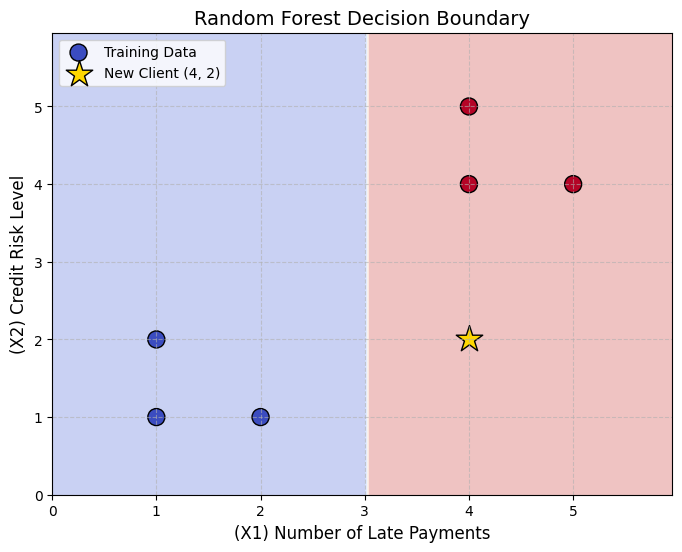

In [12]:
plt.figure(figsize=(8, 6))

# Create a mesh grid spanning the feature space
x_min, x_max = X['X1'].min() - 1, X['X1'].max() + 1
y_min, y_max = X['X2'].min() - 1, X['X2'].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.05),
                     np.arange(y_min, y_max, 0.05))

# Predict the class for every point on the grid
mesh_predictions = rf_model.predict(np.c_[xx.ravel(), yy.ravel()])
mesh_predictions = mesh_predictions.reshape(xx.shape)

# Draw the colored decision regions
plt.contourf(xx, yy, mesh_predictions, alpha=0.3, cmap='coolwarm')

# Plot the original dataset points
scatter = plt.scatter(X['X1'], X['X2'], c=y, cmap='coolwarm',
                      edgecolors='k', s=150, label='Training Data')

# Plot the new client (X1=4, X2=2) as a distinct star
plt.scatter(4, 2, c='gold', marker='*', edgecolors='k', s=400, label='New Client (4, 2)')

plt.title('Random Forest Decision Boundary', fontsize=14)
plt.xlabel('(X1) Number of Late Payments', fontsize=12)
plt.ylabel('(X2) Credit Risk Level', fontsize=12)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


**Plot 2:Visualizing the 3 Trees of the Random Forest**

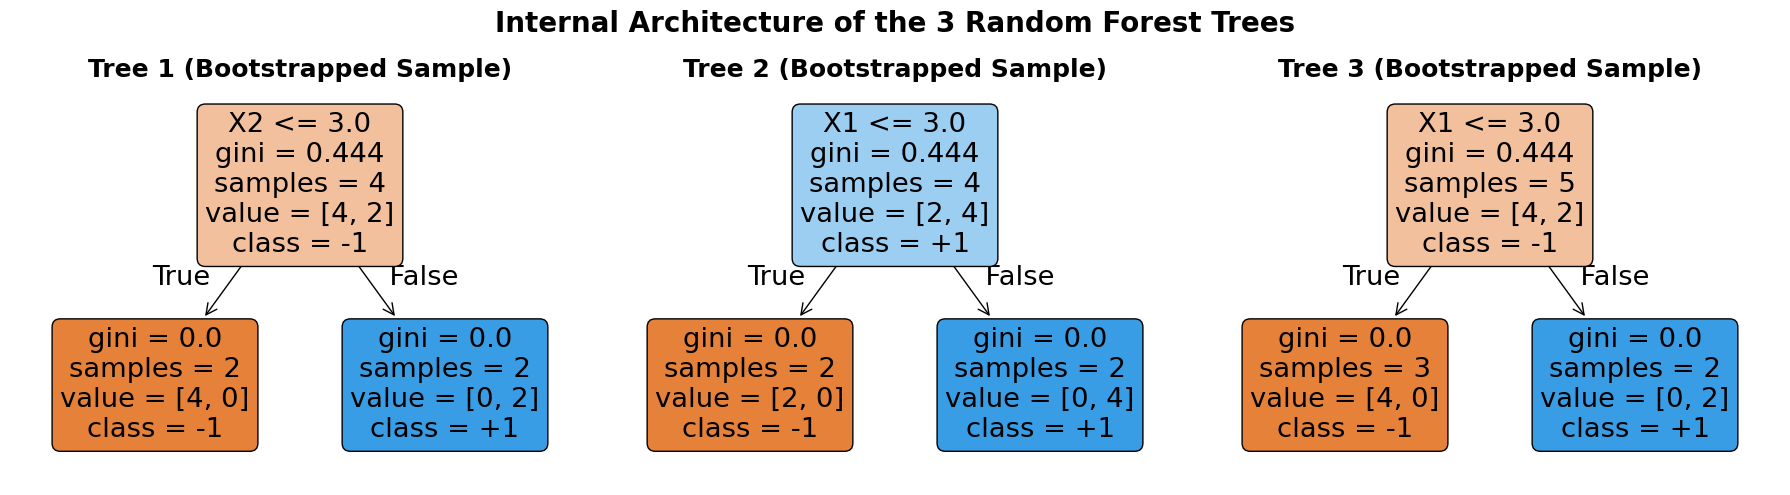

In [16]:

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(18, 5))
fig.suptitle('Internal Architecture of the 3 Random Forest Trees', fontsize=20, fontweight='bold')

for i, tree in enumerate(rf_model.estimators_):
    plot_tree(tree,
              feature_names=['X1', 'X2'],
              class_names=['-1', '+1'],
              filled=True,
              rounded=True,
              ax=axes[i])
    axes[i].set_title(f'Tree {i+1} (Bootstrapped Sample)', fontsize=18, fontweight='bold')

plt.tight_layout()
plt.show()

## CONCLUSION

 **Random Forest** transforms a collection of shallow, imperfect decision trees
into one stable and reliable classifier. By combining **Bagging** (≈63.2%
Bootstrap samples + 36.8% OOB validation) with **Feature Randomness**
(m ≈ √P variables per split) and a **Majority Vote**, the model:

- reduces overfitting compared to a single decision tree,
- provides free internal validation through the OOB score,
- remains interpretable via `feature_importances_` and tree visualization.

**On this  Dataset :**

| Item | Result |
|---|---|
| Trees | 3 |
| Max features per split | 1 |
| OOB Error Rate | 0.0% (on n=6, T=3 — not a proof of excellence) |
| Tree architecture | Depth = 1, Nodes = 3 (Decision Stumps) |
| New client (X1=4, X2=2) | Class +1 → **High Risk** |

**Economically**, Random Forest is the preferred choice in finance because
it aligns **predictive performance** with **risk diversification**,
**regulatory compliance** (Basel III, GDPR), and **efficient use of
scarce data**. It is the standard baseline for credit scoring, fraud
detection, and corporate rating.

>
> * **Random Forest** trades a little interpretability for stability,
> fairness, and generalization — exactly what financial decisions need.*